# T03 · PCA (Dimensionality Reduction + 2D Visualization)

**ใช้เมื่อโจทย์ถาม:** ทำ PCA · explained variance / cumulative · ต้องใช้กี่ component (80%/90%/95%, eigenvalue > 1, scree/elbow) ·
loadings (ตัวแปรไหนขับ PC1/PC2) · scatter 2D ระบายสีตาม class/cluster · PCA ก่อนสร้างโมเดล "ดีขึ้นไหม" · แปลงข้อมูลใหม่เป็น PC

| ขั้น | ทำอะไร |
|---|---|
| 1 | แก้ **⚙️ CONFIG** · Run All |
| 2 | อ่านผลตาม § ที่โจทย์ถาม · copy ประโยค `✍️` |

> **ต้อง standardize ก่อน PCA เสมอ** (ยกเว้นโจทย์บอกไม่ต้อง) — ไม่งั้นตัวแปรหน่วยใหญ่ (เช่น proline หลักพัน) จะครอง PC1

In [1]:
# ════════ ⚙️ CONFIG — แก้ cell นี้ให้ตรงโจทย์ ════════
DATA_PATH = "../practice/data/p4_wine.csv"
TARGET    = "cultivar"     # คอลัมน์ class ไว้ "ระบายสี" กราฟ / เทียบโมเดล (ไม่มีใส่ None)
POS_LABEL = None
ID_COL    = None           # ชื่อ/รหัสแถว (ใช้เขียน label บนจุด ถ้ามี)
DROP_COLS = []             # คอลัมน์ที่ไม่ใช้ทำ PCA
FEATURES  = None           # list feature ที่จะใช้ · None = ตัวเลขทุกคอลัมน์ (ยกเว้น TARGET/ID/DROP)
STANDARDIZE = True         # True = z-score ก่อน PCA (ปกติต้อง True)
VAR_TARGET  = 0.80         # เกณฑ์ cumulative variance ที่โจทย์ถาม (0.80 / 0.90 / 0.95)
N_LOADINGS  = 3            # แสดง loadings ของกี่ PC
NEW_POINT = None           # dict ข้อมูลใหม่ที่จะแปลงเป็น PC เช่น {"alcohol": 13.0, ...} · None = ข้าม
SEED, N_FOLDS = 42, 5
MISSING_MARKERS, SHEET, CSV_SEP = ["?", "", " ", "NA"], 0, ","

In [2]:
# ════════ 🔧 IMPORTS + HELPERS — ไม่ต้องแก้ cell นี้ แค่รันหลัง CONFIG ════════
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

from sklearn.model_selection import (train_test_split, StratifiedKFold, KFold, cross_validate,
                                     cross_val_predict, GridSearchCV)
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (StandardScaler, MinMaxScaler, OneHotEncoder, OrdinalEncoder,
                                   KBinsDiscretizer, LabelEncoder)
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.neighbors import KNeighborsClassifier, KNeighborsRegressor, NearestNeighbors
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.tree import (DecisionTreeClassifier, DecisionTreeRegressor, plot_tree, export_text)
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
                             roc_curve, precision_recall_curve, average_precision_score,
                             confusion_matrix, ConfusionMatrixDisplay, classification_report,
                             mean_absolute_error, mean_squared_error, r2_score,
                             silhouette_score, silhouette_samples, davies_bouldin_score)

pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

# ค่า default ถ้า CONFIG ไม่ได้กำหนดไว้ (กันลืม)
for _name, _val in {"SEED": 42, "N_FOLDS": 5, "TEST_SIZE": 0.2, "TARGET": None, "POS_LABEL": None,
                    "ID_COL": None, "DROP_COLS": [], "MISSING_MARKERS": ["?", "", " ", "NA", "N/A", "null"],
                    "SHEET": 0, "CSV_SEP": ",", "SCALE": "standard"}.items():
    globals().setdefault(_name, _val)


def load_data(path, sheet=None, sep=None, na_values=None):
    """อ่าน .csv / .xlsx / .xls → ตัดช่องว่างหัวคอลัมน์และค่า string → แปลงค่าแฝง ('?', '') เป็น NaN"""
    sheet = SHEET if sheet is None else sheet
    sep = CSV_SEP if sep is None else sep
    na_values = MISSING_MARKERS if na_values is None else na_values
    if str(path).lower().endswith((".xlsx", ".xls")):
        df = pd.read_excel(path, sheet_name=sheet)
    else:
        df = pd.read_csv(path, sep=sep)
    df.columns = [str(c).strip() for c in df.columns]
    for c in df.columns:
        if not pd.api.types.is_numeric_dtype(df[c]) and not pd.api.types.is_bool_dtype(df[c]):
            df[c] = df[c].map(lambda v: v.strip() if isinstance(v, str) else v)
    df = df.replace(list(na_values), np.nan)
    # คอลัมน์ที่เป็นตัวเลขแต่ถูกอ่านเป็น text (เพราะเคยมี '?') → แปลงกลับเป็นตัวเลข
    for c in df.columns:
        if not pd.api.types.is_numeric_dtype(df[c]) and not pd.api.types.is_bool_dtype(df[c]):
            conv = pd.to_numeric(df[c], errors="coerce")
            if conv.notna().sum() == df[c].notna().sum() and df[c].notna().any():
                df[c] = conv
    print(f"โหลด {path} → {df.shape[0]} แถว × {df.shape[1]} คอลัมน์")
    return df


def check(df, target=None):
    """ตรวจข้อมูลใน 1 คำสั่ง: ขนาด · ชนิด · ค่าว่าง · unique · ตัวอย่างค่า · สัดส่วน target"""
    print("shape:", df.shape, "| แถวซ้ำ:", int(df.duplicated().sum()))
    info = pd.DataFrame({"dtype": df.dtypes.astype(str),
                         "missing": df.isna().sum(),
                         "missing_%": (df.isna().mean() * 100).round(2),
                         "unique": df.nunique(),
                         "example": [df[c].dropna().iloc[0] if df[c].notna().any() else None for c in df]})
    display(info)
    if target is not None and target in df and pd.api.types.is_numeric_dtype(df[target]) and df[target].nunique() > 15:
        print(f"target '{target}' เป็นตัวเลข (regression):")
        display(df[target].describe().to_frame().T)
    elif target is not None and target in df:
        vc = pd.concat([df[target].value_counts(dropna=False), df[target].value_counts(normalize=True, dropna=False).round(4)],
                       axis=1, keys=["count", "ratio"])
        print(f"การกระจายของ target '{target}':")
        display(vc)


def num_cols(df):
    return df.select_dtypes(include="number").columns.tolist()


def cat_cols(df):
    return [c for c in df.columns if c not in num_cols(df)]


def make_xy(df, target=None, drop=None, pos_label=None, task="classification"):
    """แยก X / y · ตัด target + DROP_COLS + ID_COL · classification 2 คลาส → y = 1 ถ้าเท่ากับ POS_LABEL"""
    target = TARGET if target is None else target
    drop = DROP_COLS if drop is None else drop
    pos_label = POS_LABEL if pos_label is None else pos_label
    d = df.dropna(subset=[target]).copy()
    removed = [c for c in list(drop) + [ID_COL] if c is not None and c in d.columns and c != target]
    X = d.drop(columns=[target] + removed)
    if task == "regression":
        y = d[target].astype(float)
        print(f"X: {X.shape} | y = '{target}' (ตัวเลข) | ตัดคอลัมน์: {removed}")
        return X, y
    raw = d[target]
    classes = sorted(raw.astype(str).unique())
    if len(classes) == 2:
        pos = str(pos_label) if pos_label is not None else classes[-1]
        if pos not in classes:
            raise ValueError(f"POS_LABEL={pos_label!r} ไม่อยู่ใน {classes} — แก้ใน CONFIG")
        neg = [c for c in classes if c != pos][0]
        y = (raw.astype(str) == pos).astype(int).rename(target)
        print(f"X: {X.shape} | y = '{target}' → 1 = {pos!r} (positive), 0 = {neg!r} | ตัดคอลัมน์: {removed}")
    else:
        y = raw.astype(str)
        print(f"X: {X.shape} | y = '{target}' มี {len(classes)} คลาส {classes} (multiclass → ใช้ macro avg) | ตัดคอลัมน์: {removed}")
    return X, y


def is_binary(y):
    return pd.Series(y).nunique() == 2


def build_prep(X, scale="config", num_impute="median", onehot=True):
    """preprocessing ที่ fit เฉพาะ train (ใส่ใน Pipeline → ไม่ leak)
    ตัวเลข: เติมค่าว่าง (median) → scale ('standard' z-score | 'minmax' 0–1 | None)
    หมวดหมู่: เติมค่าว่าง (ค่าที่พบบ่อยสุด) → one-hot"""
    if scale == "config":                      # ไม่ระบุ → ใช้ SCALE จาก CONFIG · ส่ง None = ไม่ scale
        scale = SCALE
    nums, cats = num_cols(X), cat_cols(X)
    scaler = {"standard": StandardScaler(), "minmax": MinMaxScaler()}.get(scale, "passthrough")
    num_pipe = Pipeline([("impute", SimpleImputer(strategy=num_impute)), ("scale", scaler)])
    enc = OneHotEncoder(handle_unknown="ignore", sparse_output=False) if onehot else \
        OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1)
    cat_pipe = Pipeline([("impute", SimpleImputer(strategy="most_frequent")), ("encode", enc)])
    return ColumnTransformer([("num", num_pipe, nums), ("cat", cat_pipe, cats)],
                             verbose_feature_names_out=False)


def make_pipe(model, X, scale="config", **kw):
    """Pipeline = preprocessing (fit บน train fold เท่านั้น) + model"""
    return Pipeline([("prep", build_prep(X, scale=scale, **kw)), ("model", model)])


def get_cv(task="classification", n=None):
    n = N_FOLDS if n is None else n
    if task == "regression":
        return KFold(n_splits=n, shuffle=True, random_state=SEED)
    return StratifiedKFold(n_splits=n, shuffle=True, random_state=SEED)


def cls_scoring(y):
    if is_binary(y):
        return {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1"}
    return {"accuracy": "accuracy", "precision": "precision_macro", "recall": "recall_macro", "f1": "f1_macro"}


def evaluate(name, model, X, y, cv=None, settings="", train=False):
    """classification ด้วย cross-validation → 1 แถว (ค่าเฉลี่ยทุก fold) ใช้ต่อเป็นตารางเปรียบเทียบ"""
    cv = get_cv() if cv is None else cv
    r = cross_validate(model, X, y, cv=cv, scoring=cls_scoring(y), return_train_score=train)
    row = {"model": name, "settings": settings}
    row.update({m: r[f"test_{m}"].mean() for m in ["accuracy", "precision", "recall", "f1"]})
    row["f1_std"] = r["test_f1"].std()
    if train:
        row["train_accuracy"] = r["train_accuracy"].mean()
    return row


def evaluate_holdout(name, model, X_tr, y_tr, X_te, y_te, settings=""):
    """classification แบบ hold-out: fit บน train → วัดบน test"""
    model.fit(X_tr, y_tr)
    p = model.predict(X_te)
    avg = "binary" if is_binary(y_tr) else "macro"
    return {"model": name, "settings": settings,
            "accuracy": accuracy_score(y_te, p),
            "precision": precision_score(y_te, p, average=avg, zero_division=0),
            "recall": recall_score(y_te, p, average=avg, zero_division=0),
            "f1": f1_score(y_te, p, average=avg, zero_division=0),
            "train_accuracy": accuracy_score(y_tr, model.predict(X_tr))}


def reg_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"MAE": mean_absolute_error(y_true, y_pred), "MSE": mse, "RMSE": np.sqrt(mse),
            "R2": r2_score(y_true, y_pred)}


def evaluate_reg(name, model, X, y, cv=None, settings=""):
    """regression ด้วย cross-validation → MAE / MSE / RMSE / R²"""
    cv = get_cv("regression") if cv is None else cv
    r = cross_validate(model, X, y, cv=cv,
                       scoring=["neg_mean_absolute_error", "neg_mean_squared_error", "r2"])
    mse = -r["test_neg_mean_squared_error"].mean()
    return {"model": name, "settings": settings, "MAE": -r["test_neg_mean_absolute_error"].mean(),
            "MSE": mse, "RMSE": np.sqrt(mse), "R2": r["test_r2"].mean()}


def show_cm(y_true, y_pred, title="Confusion matrix"):
    """confusion matrix (แถว = actual, คอลัมน์ = predicted) + classification report"""
    labels = sorted(pd.Series(y_true).unique(), key=str)
    cm = confusion_matrix(y_true, y_pred, labels=labels)
    display(pd.DataFrame(cm, index=[f"actual {l}" for l in labels], columns=[f"pred {l}" for l in labels]))
    if len(labels) == 2:
        tn, fp, fn, tp = cm.ravel()
        print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")
    print(classification_report(y_true, y_pred, digits=4, zero_division=0))
    fig, ax = plt.subplots(figsize=(4, 3.4))
    ConfusionMatrixDisplay(cm, display_labels=labels).plot(ax=ax, colorbar=False, cmap="Blues")
    ax.set_title(title); ax.grid(False); plt.show()
    return cm


def top_k(grid, n=10):
    """ตารางผล GridSearchCV เรียงจากดีสุด"""
    res = pd.DataFrame(grid.cv_results_)
    cols = [c for c in res if c.startswith("param_")] + \
           [c for c in res if c.startswith("mean_test_") or c.startswith("mean_train_")]
    key = f"mean_test_{grid.refit}" if isinstance(grid.refit, str) else "mean_test_score"
    return res[cols].sort_values(key, ascending=False).head(n).reset_index(drop=True)


def results_table(rows, sort_by=None, ascending=False):
    t = pd.DataFrame(rows)
    if sort_by:
        t = t.sort_values(sort_by, ascending=ascending)
    display(t.reset_index(drop=True))
    return t.reset_index(drop=True)


def say_compare(table, metric="f1", baseline_name=None, higher_is_better=True):
    """พิมพ์ประโยคตีความสำเร็จรูปจากตารางผล (copy ไปใส่คำตอบได้เลย)"""
    t = table.sort_values(metric, ascending=not higher_is_better)
    best = t.iloc[0]
    msg = f"✍️ โมเดลที่ดีที่สุดตาม {metric} คือ {best['model']}"
    if str(best.get("settings", "")):
        msg += f" ({best['settings']})"
    msg += f" ได้ {metric} = {best[metric]:.4f}"
    if baseline_name is not None and baseline_name in set(table["model"]):
        b = table.loc[table["model"] == baseline_name].iloc[0]
        diff = best[metric] - b[metric]
        msg += f" เทียบกับ baseline ({baseline_name}) ที่ได้ {b[metric]:.4f} ต่างกัน {diff:+.4f}"
        if "accuracy" in table and metric != "accuracy":
            msg += f" (baseline accuracy = {b['accuracy']:.4f} แต่ {metric} ต่ำ → accuracy อย่างเดียวหลอกได้ถ้าคลาสไม่สมดุล)"
    print(msg)


def new_data(source):
    """ข้อมูลใหม่ที่จะทำนาย: path ไฟล์ (str) / dict 1 แถว / list ของ dict / DataFrame"""
    if source is None:
        return None
    if isinstance(source, str):
        return load_data(source)
    if isinstance(source, dict):
        return pd.DataFrame([source])
    if isinstance(source, list):
        return pd.DataFrame(source)
    return source.copy()


def align_new(df_new, X_ref):
    """จัดคอลัมน์ข้อมูลใหม่ให้ตรงกับ X ที่ใช้ train (คอลัมน์ที่ขาดเติม NaN → imputer จัดการ)"""
    missing = [c for c in X_ref.columns if c not in df_new.columns]
    if missing:
        print("⚠️ ข้อมูลใหม่ขาดคอลัมน์:", missing, "→ เติม NaN (imputer จะเติมให้)")
    return df_new.reindex(columns=X_ref.columns)

print("✅ helpers พร้อม | SEED =", SEED, "| N_FOLDS =", N_FOLDS)

✅ helpers พร้อม | SEED = 42 | N_FOLDS = 5


## §1 โหลด + เลือก feature ตัวเลข

In [3]:
df = load_data(DATA_PATH)
skip = [c for c in [TARGET, ID_COL] + list(DROP_COLS) if c]
feats = FEATURES or [c for c in num_cols(df) if c not in skip]
data = df.dropna(subset=feats).reset_index(drop=True)
print(f"ใช้ {len(feats)} feature: {feats}")
print(f"แถว {len(df)} → ตัดแถวที่มีค่าว่าง {len(df) - len(data)} → {len(data)}")
display(data[feats].describe().T[["mean", "std", "min", "max"]])
print("✍️ ช่วงของตัวแปรต่างกันมาก (std ตั้งแต่ %.3f ถึง %.3f) → ต้อง standardize ก่อน PCA" % (data[feats].std().min(), data[feats].std().max()))

โหลด ../practice/data/p4_wine.csv → 178 แถว × 14 คอลัมน์
ใช้ 13 feature: ['alcohol', 'malic_acid', 'ash', 'alcalinity_of_ash', 'magnesium', 'total_phenols', 'flavanoids', 'nonflavanoid_phenols', 'proanthocyanins', 'color_intensity', 'hue', 'od280_od315_of_diluted_wines', 'proline']
แถว 178 → ตัดแถวที่มีค่าว่าง 0 → 178


,mean,std,min,max
alcohol,13.0006,0.8118,11.0300,14.8300
malic_acid,2.3363,1.1171,0.7400,5.8000
ash,2.3665,0.2743,1.3600,3.2300
alcalinity_of_ash,19.4949,3.3396,10.6000,30.0000
magnesium,99.7416,14.2825,70.0000,162.0000
total_phenols,2.2951,0.6259,0.9800,3.8800
flavanoids,2.0293,0.9989,0.3400,5.0800
nonflavanoid_phenols,0.3619,0.1245,0.1300,0.6600
proanthocyanins,1.5909,0.5724,0.4100,3.5800
color_intensity,5.0581,2.3183,1.2800,13.0000


✍️ ช่วงของตัวแปรต่างกันมาก (std ตั้งแต่ 0.124 ถึง 314.907) → ต้อง standardize ก่อน PCA


## §2 Standardize → PCA (ทุก component) → ตาราง explained variance
- **eigenvalue** = ความแปรปรวนของ PC (ข้อมูล z-score: ผลรวม eigenvalue = จำนวน feature)
- **explained variance ratio** = eigenvalue / ผลรวม · **cumulative** = สะสม

In [4]:
scaler = StandardScaler() if STANDARDIZE else None
Z = scaler.fit_transform(data[feats]) if STANDARDIZE else data[feats].values
pca_full = PCA(random_state=SEED).fit(Z)
ev = pd.DataFrame({"PC": [f"PC{i+1}" for i in range(len(feats))],
                   "eigenvalue": pca_full.explained_variance_,
                   "explained_%": pca_full.explained_variance_ratio_ * 100,
                   "cumulative_%": pca_full.explained_variance_ratio_.cumsum() * 100})
display(ev.round(3))
n_target = int(np.argmax(ev["cumulative_%"].values >= VAR_TARGET * 100) + 1)
n_kaiser = int((ev["eigenvalue"] > 1).sum())
print(f"✍️ ต้องใช้ {n_target} component จึงอธิบายความแปรปรวนได้ ≥ {VAR_TARGET:.0%} (ได้ {ev['cumulative_%'][n_target-1]:.2f}%)")
print(f"✍️ เกณฑ์ Kaiser (eigenvalue > 1) เก็บ {n_kaiser} component")
print(f"✍️ PC1 อธิบายได้ {ev['explained_%'][0]:.2f}% · PC1+PC2 = {ev['cumulative_%'][1]:.2f}% (ภาพ 2D แสดงข้อมูลได้ประมาณนี้)")

,PC,eigenvalue,explained_%,cumulative_%
0,PC1,4.7320,36.1990,36.1990
1,PC2,2.5110,19.2070,55.4060
2,PC3,1.4540,11.1240,66.5300
3,PC4,0.9240,7.0690,73.5990
4,PC5,0.8580,6.5630,80.1620
5,PC6,0.6450,4.9360,85.0980
6,PC7,0.5540,4.2390,89.3370
7,PC8,0.3500,2.6810,92.0180
8,PC9,0.2910,2.2220,94.2400
9,PC10,0.2520,1.9300,96.1700


✍️ ต้องใช้ 5 component จึงอธิบายความแปรปรวนได้ ≥ 80% (ได้ 80.16%)
✍️ เกณฑ์ Kaiser (eigenvalue > 1) เก็บ 3 component
✍️ PC1 อธิบายได้ 36.20% · PC1+PC2 = 55.41% (ภาพ 2D แสดงข้อมูลได้ประมาณนี้)


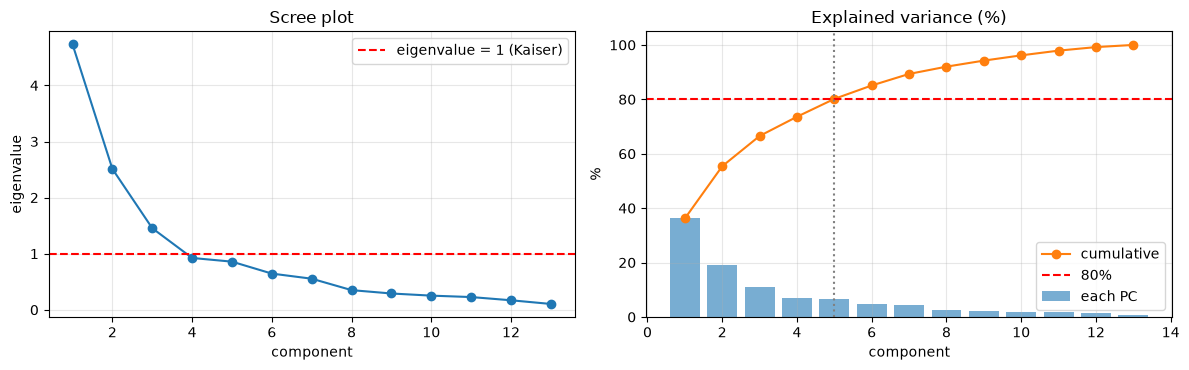

In [5]:
# Scree plot + cumulative
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(range(1, len(ev) + 1), ev["eigenvalue"], "o-"); ax[0].axhline(1, color="r", ls="--", label="eigenvalue = 1 (Kaiser)")
ax[0].set(title="Scree plot", xlabel="component", ylabel="eigenvalue"); ax[0].legend()
ax[1].bar(range(1, len(ev) + 1), ev["explained_%"], alpha=.6, label="each PC")
ax[1].plot(range(1, len(ev) + 1), ev["cumulative_%"], "o-", color="C1", label="cumulative")
ax[1].axhline(VAR_TARGET * 100, color="r", ls="--", label=f"{VAR_TARGET:.0%}"); ax[1].axvline(n_target, color="gray", ls=":")
ax[1].set(title="Explained variance (%)", xlabel="component", ylabel="%"); ax[1].legend()
plt.tight_layout(); plt.show()

**✍️ คำตอบ §2:** PC1 อธิบาย …% PC2 …% รวม …% · ต้องใช้ … component ถึง …% · Kaiser เลือก … · scree plot หักศอกที่ PC … → เลือก … component

## §3 Loadings — ตัวแปรไหนขับเคลื่อน PC แต่ละตัว
loading = น้ำหนักของตัวแปรใน PC (`components_`) · |ค่า| ใหญ่ = มีอิทธิพลมาก · เครื่องหมายบอกทิศ (ตัวแปรเครื่องหมายเดียวกันไปทางเดียวกัน)
⚠️ เครื่องหมายของทั้ง PC อาจกลับด้านได้ระหว่างโปรแกรม (ไม่ผิด)

,PC1,PC2,PC3
alcohol,0.144300,0.483700,-0.207400
malic_acid,-0.245200,0.224900,0.089000
ash,-0.002100,0.316100,0.626200
alcalinity_of_ash,-0.239300,-0.010600,0.612100
magnesium,0.142000,0.299600,0.130800
total_phenols,0.394700,0.065000,0.146200
flavanoids,0.422900,-0.003400,0.150700
nonflavanoid_phenols,-0.298500,0.028800,0.170400
proanthocyanins,0.313400,0.039300,0.149500
color_intensity,-0.088600,0.530000,-0.137300


✍️ PC1: loading สูงสุด flavanoids (+0.423), total_phenols (+0.395), od280_od315_of_diluted_wines (+0.376), proanthocyanins (+0.313)
✍️ PC2: loading สูงสุด color_intensity (+0.530), alcohol (+0.484), proline (+0.365), ash (+0.316)
✍️ PC3: loading สูงสุด ash (+0.626), alcalinity_of_ash (+0.612), alcohol (-0.207), nonflavanoid_phenols (+0.170)


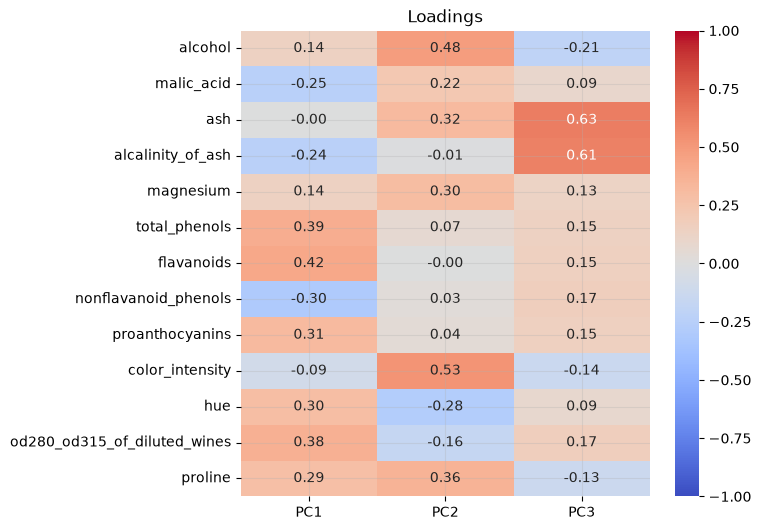

In [6]:
k = min(N_LOADINGS, len(feats))
loadings = pd.DataFrame(pca_full.components_[:k].T, index=feats, columns=[f"PC{i+1}" for i in range(k)])
display(loadings.round(4).style.background_gradient(cmap="coolwarm", vmin=-1, vmax=1))
for pc in loadings.columns:
    top = loadings[pc].abs().sort_values(ascending=False).head(4).index
    print(f"✍️ {pc}: loading สูงสุด " + ", ".join(f"{t} ({loadings.loc[t, pc]:+.3f})" for t in top))
plt.figure(figsize=(1.2 * k + 3, 0.35 * len(feats) + 1.5))
sns.heatmap(loadings, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1); plt.title("Loadings"); plt.show()

**✍️ คำตอบ §3:** PC1 ขับเคลื่อนโดย … (บวก) และ … (ลบ) → แทน "…" · PC2 ขับเคลื่อนโดย … → แทน "…" 

## §4 PCA 2D visualization (scatter PC1 × PC2 ระบายสีตาม class) + biplot

,PC1,PC2,cultivar
0,3.3168,1.4435,cultivar_0
1,2.2095,-0.3334,cultivar_0
2,2.5167,1.0312,cultivar_0
3,3.7571,2.7564,cultivar_0
4,1.0089,0.8698,cultivar_0


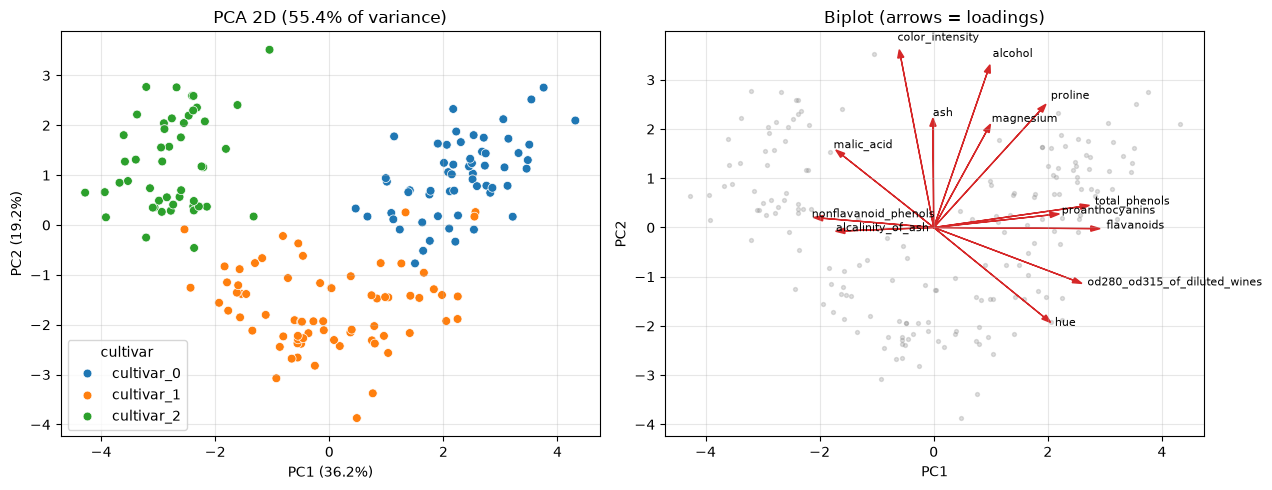

,PC1,PC2
cultivar,,
cultivar_0,2.2830,0.9680
cultivar_1,-0.0390,-1.6430
cultivar_2,-2.7480,1.2410


In [7]:
pca2 = PCA(n_components=2, random_state=SEED).fit(Z)
P = pca2.transform(Z)
scores = pd.DataFrame(P, columns=["PC1", "PC2"])
if TARGET and TARGET in data:
    scores[TARGET] = data[TARGET].astype(str).values
display(scores.head())

fig, ax = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(data=scores, x="PC1", y="PC2", hue=TARGET if TARGET in scores else None, palette="tab10", s=40, ax=ax[0])
ax[0].set(title=f"PCA 2D ({pca2.explained_variance_ratio_.sum():.1%} of variance)",
          xlabel=f"PC1 ({pca2.explained_variance_ratio_[0]:.1%})", ylabel=f"PC2 ({pca2.explained_variance_ratio_[1]:.1%})")
if ID_COL and ID_COL in data and len(data) <= 60:
    for i, name in enumerate(data[ID_COL]):
        ax[0].annotate(str(name), P[i], fontsize=7, alpha=.8)
# biplot: ลูกศร = loading ของแต่ละตัวแปร
ax[1].scatter(P[:, 0], P[:, 1], s=8, alpha=.25, color="gray")
sc = np.abs(P).max() / np.abs(pca2.components_).max() * 0.8
for j, f in enumerate(feats):
    ax[1].arrow(0, 0, pca2.components_[0, j] * sc, pca2.components_[1, j] * sc, color="C3", head_width=0.05 * sc / 3)
    ax[1].text(pca2.components_[0, j] * sc * 1.1, pca2.components_[1, j] * sc * 1.1, f, fontsize=8)
ax[1].set(title="Biplot (arrows = loadings)", xlabel="PC1", ylabel="PC2")
plt.tight_layout(); plt.show()
if TARGET and TARGET in scores:
    display(scores.groupby(TARGET)[["PC1", "PC2"]].mean().round(3))

**✍️ คำตอบ §4:** ภาพ 2D อธิบายได้ …% · คลาส … แยกออกชัดทาง PC1 (ค่าบวก/ลบ) · คลาส … กับ … ซ้อนกันบางส่วน · ลูกศร … ชี้ไปทางคลาส … แปลว่าคลาสนั้นมี … สูง

## §5 PCA ก่อนสร้างโมเดล — เทียบก่อน/หลัง (ไม่ leak: scaler + PCA อยู่ใน Pipeline)

In [8]:
if TARGET and TARGET in data:
    X, y = data[feats], data[TARGET]
    if y.nunique() == 2:
        _, y = make_xy(data[feats + [TARGET]])
    MODEL = KNeighborsClassifier(n_neighbors=5)          # ✏️ เปลี่ยนโมเดลได้ (เช่น LogisticRegression(max_iter=1000))
    rows = [evaluate("Majority baseline", DummyClassifier(), X, y),
            evaluate("Model ทุก feature (z-score)", Pipeline([("sc", StandardScaler()), ("m", MODEL)]), X, y, settings=f"{len(feats)} features")]
    for n in sorted({2, n_target, n_kaiser}):
        rows.append(evaluate(f"Model + PCA({n})", Pipeline([("sc", StandardScaler()), ("pca", PCA(n_components=n)), ("m", MODEL)]), X, y,
                             settings=f"{n} PCs"))
    rows.append(evaluate(f"Model + PCA({VAR_TARGET:.0%} var)", Pipeline([("sc", StandardScaler()), ("pca", PCA(n_components=VAR_TARGET)), ("m", MODEL)]), X, y,
                         settings=f"keep {VAR_TARGET:.0%}"))
    t = results_table(rows)
    say_compare(t, "f1", "Majority baseline")
else:
    print("ไม่มี TARGET → ข้าม §5")

,model,settings,accuracy,precision,recall,f1,f1_std
0,Majority baseline,,0.3990,0.1330,0.3333,0.1901,0.0052
1,Model ทุก feature (z-score),13 features,0.9717,0.9703,0.9765,0.9721,0.0179
2,Model + PCA(2),2 PCs,0.9665,0.9702,0.9687,0.9679,0.0206
3,Model + PCA(3),3 PCs,0.9719,0.9737,0.9757,0.9737,0.0010
4,Model + PCA(5),5 PCs,0.9719,0.9694,0.9765,0.9716,0.0174
5,Model + PCA(80% var),keep 80%,0.9719,0.9694,0.9765,0.9716,0.0174


✍️ โมเดลที่ดีที่สุดตาม f1 คือ Model + PCA(3) (3 PCs) ได้ f1 = 0.9737 เทียบกับ baseline (Majority baseline) ที่ได้ 0.1901 ต่างกัน +0.7836 (baseline accuracy = 0.3990 แต่ f1 ต่ำ → accuracy อย่างเดียวหลอกได้ถ้าคลาสไม่สมดุล)


**✍️ คำตอบ §5:** ใช้ PCA … component ได้ F1 … เทียบกับใช้ทุก feature … → ลดมิติจาก … เหลือ … โดยเสียความแม่นยำเล็กน้อย/ไม่เสีย (หรือดีขึ้นเพราะตัด noise)

## §6 แปลงข้อมูลใหม่เป็นคะแนน PC (ใช้ scaler + PCA ตัวเดิม)

In [9]:
if NEW_POINT is not None:
    new = new_data(NEW_POINT)[feats]
    z_new = scaler.transform(new) if STANDARDIZE else new.values
    print("z-score:", np.round(z_new, 3)); print("PC1, PC2 =", np.round(pca2.transform(z_new), 4))
else:
    # ตัวอย่าง: แถวแรกของข้อมูล — PC = z · loading (ผลคูณจุด)
    z0 = Z[0]; print("แถวแรก z-score:", np.round(z0, 3))
    print("PC1 = Σ z·loading =", round(float(z0 @ pca2.components_[0]), 4), "| PC2 =", round(float(z0 @ pca2.components_[1]), 4))
    print("(ตรงกับ scores.iloc[0]:", np.round(P[0], 4), ")")

แถวแรก z-score: [ 1.519 -0.562  0.232 -1.17   1.914  0.809  1.035 -0.66   1.225  0.252
  0.362  1.848  1.013]
PC1 = Σ z·loading = 3.3168 | PC2 = 1.4435
(ตรงกับ scores.iloc[0]: [3.3168 1.4435] )


## §7 Save คะแนน PC (ถ้าต้องส่ง)

In [10]:
scores.to_csv("t03_pca_scores.csv", index=False); print("saved t03_pca_scores.csv")

saved t03_pca_scores.csv
